# Wrangling and Stats Models Review

First, packages. Statsmodels is the primary statistical anlaysis package in python, as is numpy for numeric operations. Pandas is the primary for data wrangling. 

There are two calls primarily for statsmodels ... the api and the formulas api

In [244]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

Statistical tests will be in scientific python SciPy. This one is different. We want to import the stats library

In [245]:
from scipy import stats

Numpy and pandas

In [246]:
import numpy as np
import pandas as pd

get data

In [247]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

titanic = pd.read_csv(url)
titanic_raw = pd.read_csv(url)

# Goals

1. Inspect and explore
- [ ] Get the number of rows and columns.
- [ ] Display the first 10 rows.
- [ ] Display the last 5 rows.
- [ ] List all column names.
- [ ] Identify the data type of every column.
- [ ] Generate descriptive statistics for numeric variables.
- [ ] Generate descriptive statistics for categorical variables.
- [ ] Count unique values in every column.
- [ ] Get frequency counts for class, sex, and embarked.
- [ ] Calculate the percentage of missing values in every column, sorted descending.
2. Clean the data
- [ ] Count fully duplicated rows.
- [ ] Identify which rows are duplicated.
- [ ] Remove duplicates from a working copy.
- [ ] Check for missing values in age, fare, and embarked.
- [ ] Replace missing age values with the median age.
- [ ] Replace missing embarked values with the most frequent category.
- [ ] Convert class to an ordered categorical variable.
- [ ] Rename sibsp and parch to more descriptive column names.
- [ ] Verify the number of rows before and after cleaning.
3. Select, filter, and sort
- [ ] Select only age, sex, class, fare, and survived.
- [ ] Filter passengers older than 30.
- [ ] Filter female passengers in first class.
- [ ] Filter passengers in first or second class.
- [ ] Filter passengers aged 18–40 who paid more than $50.
- [ ] Filter passengers with missing deck values.
- [ ] Sort passengers by fare, highest first.
- [ ] Find the 10 oldest passengers.
- [ ] Find the 5 highest fares within each passenger class.
4. Mutate and recode variables
- [ ] Create family_size from sibsp and parch, including the passenger.
- [ ] Create is_alone based on family_size.
- [ ] Create fare_per_person using fare and family_size.
- [ ] Create age_group with categories: child, young adult, middle-aged, senior.
- [ ] Create a binary variable identifying first-class passengers.
- [ ] Recode sex into numeric indicators.
- [ ] Collapse embarked into two categories: Southampton vs. other.
- [ ] Create a variable indicating whether fare is above the overall median.
- [ ] Create a log-transformed fare variable, handling zero fares.
- [ ] Create a categorical variable representing fare quartiles.
5. Group and summarize
- [ ] Calculate mean fare by passenger class.
- [ ] Calculate median age by sex.
- [ ] Calculate survival rate by sex.
- [ ] Calculate survival rate by class.
- [ ] Calculate survival rate by sex and class.
- [ ] Calculate passenger count, mean age, median fare, and survival rate by class in one operation.
- [ ] Calculate the same metrics grouped by sex and class.
- [ ] Count distinct embarkation ports represented in each class.
- [ ] Calculate the proportion of all passengers belonging to each class.
- [ ] Identify which age group had the highest survival rate.
6. Group-wise transformations and window functions
- [ ] Add each passenger's class-average fare as a new column without collapsing rows.
- [ ] Calculate each passenger's fare minus their class-average fare.
- [ ] Standardize fare within each passenger class (within-class z-score).
- [ ] Rank passengers by fare within each class.
- [ ] Calculate each passenger's percentile rank for fare within their class.
- [ ] Calculate cumulative fare after sorting passengers by fare.
- [ ] Calculate the difference in fare between consecutive passengers after sorting.
- [ ] Identify the top three highest-paying passengers within each class.
7. Pivot and reshape
- [ ] Create a survival-rate table with class as rows and sex as columns.
- [ ] Create a passenger-count table with class as rows and embarkation port as columns.
- [ ] Create a pivot table showing mean age by sex and survival status.
- [ ] Create a pivot table with multiple summary statistics for fare.
- [ ] Convert a wide summary table into long format.
- [ ] Convert that long table back into wide format.
- [ ] Create a contingency table of sex × survival.
- [ ] Create a contingency table of class × survival with row percentages.
8. Joins and combining data
- [ ] Create a separate DataFrame containing mean fare by class.
- [ ] Left-join that summary back onto the passenger-level dataset.
- [ ] Verify the join did not unexpectedly increase the number of rows.
- [ ] Create a lookup table mapping embarkation codes to port names.
- [ ] Join the lookup table to the passenger dataset.
- [ ] Practice inner, left, right, and outer joins using small subsets.
- [ ] Split the dataset into male and female passengers, then concatenate them back together.
- [ ] Identify unmatched rows after a join.
9. Missing-data and quality checks
- [ ] Compare mean age before and after imputation.
- [ ] Calculate missing-age percentages by sex and class using the original data.
- [ ] Identify columns with more than 20% missing values.
- [ ] Check for impossible ages or negative fares.
- [ ] Check that survived contains only 0 and 1.
- [ ] Check whether family_size is always at least 1.
- [ ] Confirm that no unexpected rows were lost during transformations.
- [ ] Create a final analysis-ready DataFrame containing only the variables needed for modeling.
10. Interview-style challenges
- [ ] Find the passenger class with the highest survival rate among children.
- [ ] Find the sex × class combination with the largest number of passengers.
- [ ] Calculate the difference in survival rates between men and women within each class.
- [ ] Identify passengers whose fare exceeds twice the median fare of their class.
- [ ] Calculate the proportion of passengers traveling alone within each class.
- [ ] Find the three age groups with the highest average fare.
- [ ] Produce a single summary table containing passenger counts, survival rates, average age, median fare, and percentage traveling alone, grouped by sex and class.

Vet the dataset

## 1 - Inspection

In [248]:
#rows
len(titanic)

891

In [249]:
#rows
titanic.shape[0]

891

In [250]:
#cols
len(titanic.columns)

15

In [251]:
#cols
titanic.shape[1]

15

In [252]:
#first 15 rows
titanic.iloc[0:15,]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False


In [253]:
#last 5 rows
titanic.iloc[-5:,]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [254]:
# all columns as list
titanic.columns.to_list()

['survived',
 'pclass',
 'sex',
 'age',
 'sibsp',
 'parch',
 'fare',
 'embarked',
 'class',
 'who',
 'adult_male',
 'deck',
 'embark_town',
 'alive',
 'alone']

In [255]:
#datatypes
titanic.dtypes

survived         int64
pclass           int64
sex             object
age            float64
sibsp            int64
parch            int64
fare           float64
embarked        object
class           object
who             object
adult_male        bool
deck            object
embark_town     object
alive           object
alone             bool
dtype: object

In [256]:
# make a custom dataframe. Each of these is a pandas series and will align on index (column name)

(
    pd.DataFrame({
        "dtypes": titanic.dtypes,
        "count": titanic.count(),
        "unique count": titanic.nunique()
    })

    # use .join since we want to use row indexes (rather than .merge, which uses a key we provide)
    .join(
        titanic.head().T,
        how="inner"
    )
    
)

,dtypes,count,unique count,0,1,2,3,4
survived,int64,891,2,0,1,1,1,0
pclass,int64,891,3,3,1,3,1,3
sex,object,891,2,male,female,female,female,male
age,float64,714,88,22.0,38.0,26.0,35.0,35.0
sibsp,int64,891,7,1,1,0,1,0
parch,int64,891,7,0,0,0,0,0
fare,float64,891,248,7.25,71.2833,7.925,53.1,8.05
embarked,object,889,3,S,C,S,S,S
class,object,891,3,Third,First,Third,First,Third
who,object,891,3,man,woman,woman,woman,man


In [257]:
# glimpse
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


In [258]:
#head and tail
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [259]:
titanic.tail()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


Descriptives for numbers

In [260]:
(
    titanic
    .select_dtypes(include="number")
    .describe()
    .T
    )

,count,mean,std,min,25%,50%,75%,max
survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
sibsp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


Descriptives for object/category types (everything else)

In [261]:
(
    titanic
    .select_dtypes(include=["object", "category"])
    .describe()
    .T
    )

,count,unique,top,freq
sex,891,2,male,577
embarked,889,3,S,644
class,891,3,Third,491
who,891,3,man,537
deck,203,7,C,59
embark_town,889,3,Southampton,644
alive,891,2,no,549


In [262]:
#faster
display(
    titanic
    .describe(include=["number"])
)

display(
    titanic
    .describe(include=['object', 'category'])
)

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


,sex,embarked,class,who,deck,embark_town,alive
count,891,889,891,891,203,889,891
unique,2,3,3,3,7,3,2
top,male,S,Third,man,C,Southampton,no
freq,577,644,491,537,59,644,549


Value counts normalized or not

In [263]:
titanic["sex"].value_counts(normalize=True)

sex
male      0.647587
female    0.352413
Name: proportion, dtype: float64

In [264]:
titanic["embarked"].value_counts()

embarked
S    644
C    168
Q     77
Name: count, dtype: int64

Table of counts and proportions

In [265]:
pd.DataFrame({
    "n": titanic["embarked"].value_counts(dropna=False),
    "prop": titanic["embarked"].value_counts(normalize=True, dropna=False),    
})

,n,prop
embarked,,
S,644,0.722783
C,168,0.188552
Q,77,0.086420
NaN,2,0.002245


In [266]:
# or as a chain
(
    titanic["embarked"]
    .value_counts()
    .to_frame("n")
    .assign(
        prop = lambda d: d["n"] / sum(d["n"])
    )
)

,n,prop
embarked,,
S,644,0.724409
C,168,0.188976
Q,77,0.086614


In [267]:
# Calculate the percentage of missing values in every column, sorted descending.
(
    titanic.isna().sum()
    .to_frame("nmiss")
    .assign(
        propmiss = lambda d: d["nmiss"]/titanic.shape[0]
    )
    .sort_values("propmiss", ascending=False)
)

,nmiss,propmiss
deck,688,0.772166
age,177,0.198653
embarked,2,0.002245
embark_town,2,0.002245
survived,0,0.000000
pclass,0,0.000000
sex,0,0.000000
sibsp,0,0.000000
parch,0,0.000000
fare,0,0.000000


concat stack rows

In [268]:
a = titanic.iloc[:10]
b = titanic.iloc[10:20]

In [269]:
#bind rows
# axis is 0 because we are bindiding ROWS (0 = rows)
pd.concat([a, b], axis=0)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False


## 2 - clean

total duplicates

In [270]:
#total duplicated rows 
len(titanic) - len(titanic.drop_duplicates())

107

In [271]:
# or
titanic.duplicated().sum()

np.int64(107)

duplicated rows

In [272]:
titanic[
    titanic.duplicated()
]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
47,1,3,female,NaN,0,0,7.7500,Q,Third,woman,False,NaN,Queenstown,yes,True
76,0,3,male,NaN,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True
77,0,3,male,NaN,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
87,0,3,male,NaN,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
95,0,3,male,NaN,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
870,0,3,male,26.0,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True
877,0,3,male,19.0,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True
878,0,3,male,NaN,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True
884,0,3,male,25.0,0,0,7.0500,S,Third,man,True,NaN,Southampton,no,True


using titanic.duplicated() is a pythonic way of flagging, counting duplicate rows

In [273]:
# boring
(
    titanic
    .loc[
        ~titanic.duplicated()
    ]
)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
885,0,3,female,39.0,0,5,29.1250,Q,Third,woman,False,NaN,Queenstown,no,False
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [274]:
#pythonic
titanic.drop_duplicates()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
885,0,3,female,39.0,0,5,29.1250,Q,Third,woman,False,NaN,Queenstown,no,False
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


### fill missing values

Find missings on age, replace them with median. for categorical, replace with mode

In [275]:
#missings on age
titanic["age"].isna().sum()

np.int64(177)

.fillna() is our best friend

- Can give it a series, in which case it will use row indexes
- Can give it a scalar, in which case it will just sub in the scalar

### Scalars

In [276]:
# best is use fillna
titanic2 = titanic.copy()

med = titanic2["age"].median()
titanic2["age"] = titanic2["age"].fillna(med)

In [277]:
# get the mode and fill for categorical
# MODE RETURNS A SERIES THERE CAN BE MULTIPLE MODES
mode = titanic2["embarked"].mode().iloc[0]
titanic2["embarked"] = titanic2["embarked"].fillna(mode)

### Series version

use .groupby() to make a grouped version of the df, then .transform() to make new series of same length. You can also manually make a new series if needed

Steps
- df
- groupby
- select column of interest
- select transform of interest

In [278]:
titanic2 = titanic.copy()

#returns series
age_series = titanic2.groupby(["class", "sex"])["age"].transform("median")

#shove series into fillna
titanic2["age"] = titanic2["age"].fillna(
    age_series
)

if you really wanted to, you could manually build a series and shove it in

In [279]:
mode_series = \
    pd.Series(
        np.repeat(
            titanic2["embarked"].mode().iloc[0],
            len(titanic2)
        ),
        index = titanic2.index
    )

titanic2["embarked"] = \
    titanic2["embarked"].fillna(
        mode_series
    )

### Ordered

make an ordered categorical

In [280]:
titanic["class"] = pd.Categorical(
    titanic["class"],
    categories = ["Third", "Second", "First"],
    ordered = True
)

titanic["class"]

0       Third
1       First
2       Third
3       First
4       Third
        ...  
886    Second
887     First
888     Third
889     First
890     Third
Name: class, Length: 891, dtype: category
Categories (3, object): ['Third' < 'Second' < 'First']

Can now use for sorts

In [281]:
titanic.sort_values('class', ascending = False)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
445,1,1,male,4.0,0,2,81.8583,S,First,child,False,A,Southampton,yes,False
724,1,1,male,27.0,1,0,53.1000,S,First,man,True,E,Southampton,yes,False
318,1,1,female,31.0,0,2,164.8667,S,First,woman,False,C,Southampton,yes,False
710,1,1,female,24.0,0,0,49.5042,C,First,woman,False,C,Cherbourg,yes,True
311,1,1,female,18.0,2,2,262.3750,C,First,woman,False,B,Cherbourg,yes,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
376,1,3,female,22.0,0,0,7.2500,S,Third,woman,False,NaN,Southampton,yes,True
378,0,3,male,20.0,0,0,4.0125,C,Third,man,True,NaN,Cherbourg,no,True
379,0,3,male,19.0,0,0,7.7750,S,Third,man,True,NaN,Southampton,no,True
381,1,3,female,1.0,0,2,15.7417,C,Third,child,False,NaN,Cherbourg,yes,False


sort descending class, then ascending fare


In [340]:
titanic.sort_values(["class", "fare"], ascending = [False, True])

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,age_group,embarked_code,fare_gt_mdn,fare_qt,fare_class_mean
263,0,1,male,40.0,0,0,0.00,S,First,man,True,B,Southampton,no,True,middle_age,S,False,"(-0.001, 7.91]",84.154687
633,0,1,male,NaN,0,0,0.00,S,First,man,True,NaN,Southampton,no,True,NaN,S,False,"(-0.001, 7.91]",84.154687
806,0,1,male,39.0,0,0,0.00,S,First,man,True,A,Southampton,no,True,young_adult,S,False,"(-0.001, 7.91]",84.154687
815,0,1,male,NaN,0,0,0.00,S,First,man,True,B,Southampton,no,True,NaN,S,False,"(-0.001, 7.91]",84.154687
822,0,1,male,38.0,0,0,0.00,S,First,man,True,NaN,Southampton,no,True,young_adult,S,False,"(-0.001, 7.91]",84.154687
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
201,0,3,male,NaN,8,2,69.55,S,Third,man,True,NaN,Southampton,no,False,NaN,S,True,"(31.0, 512.329]",13.675550
324,0,3,male,NaN,8,2,69.55,S,Third,man,True,NaN,Southampton,no,False,NaN,S,True,"(31.0, 512.329]",13.675550
792,0,3,female,NaN,8,2,69.55,S,Third,woman,False,NaN,Southampton,no,False,NaN,S,True,"(31.0, 512.329]",13.675550
846,0,3,male,NaN,8,2,69.55,S,Third,man,True,NaN,Southampton,no,False,NaN,S,True,"(31.0, 512.329]",13.675550


In [282]:
# or comparisons
titanic["class"] > "Second"

0      False
1       True
2      False
3       True
4      False
       ...  
886    False
887     True
888    False
889     True
890    False
Name: class, Length: 891, dtype: bool

In [283]:
titanic2.rename(
    columns= {
        "sibsp": "newname"
    }
)

,survived,pclass,sex,age,newname,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,21.5,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [284]:
print(len(titanic))


891


In [285]:
print(len(titanic2))

891


### Cuts and case when

np.select() is a godsend. it's case when. A few things
- unlike R, BOOL & BOOL fails because the "&" is evalued first. So, put the logical conditions in () first
- np.select() defaults to 0, which can cause type issues. always provide a default

Select always has 
- a first [] for conditions
- a matching [] for outputs
- a default = 

The above can simplify. in case-when logic, it picks the first one that fits. so you can get rid of the double bounds

In [286]:
df = titanic.copy()

df = (
    df
    .assign(
        age_group = lambda x:
            np.select(
                [
                    x["age"] < 18,
                    x["age"] < 40,
                    x["age"] < 65,
                    x["age"] >= 65
                ],
                [
                    "child",
                    "young_adult",
                    "middle_age",
                    "older"
                ],
                default="undefined"
            )
    )
)

For binning, pd.cut() is your friend, however
- use 0 for lower bound
- use float("inf") to do infinite upper bound

There is also a question as to whether the second value goes in the FIRST BIN or the SECOND BIN
- "right = True" puts them in the first bin (0 to 18 inclusive)
- "right = False" puts them in the second bin (0 up to 18 exclusive)

right = False is very consistent with "start inclusive, end exclusive" which is a python convention

In [287]:
titanic["age_group"] = pd.cut(
    titanic["age"],
    bins = [0,18,40,65, float("inf")],
    labels = ["child", "young_adult", "middle_age", "older"],
    right = False
)

# 2.x - grouped analysis

.transform() performs a computation and returns values aligned with the original rows, rather than collapsing them.



.groupby() determines which observations contribute to each computation, based on one or more grouping variables.



.assign() puts the resulting Series into a new or existing DataFrame column.

Summarize by group:
- always give colname = tuple
- tuple should be 
    - name of first variable
    - name of function ('size' 'min' 'mean' etc)
    - or can be a lambda x: where x is the column in question
- groupby learnings
    - dropna = False in grouping if you want to keep missing-key groups
    - observed=True is default ... it will report EVERY group even if there are no values there. set observed=False to only see values for groups that are in the query

In [288]:
(
    df
    .groupby("class", dropna = False, observed=True)
    .agg(
        n_passengers = ("survived", "size"), #size is all rows
        n_with_surv = ("survived", "count"), #count is nonmissing
        survival = ("survived", "mean"),
        median_fare = ("fare", "median"),
        fare_ssq = ("fare", lambda x: np.sum((x-np.mean(x))**2))
    )
    .reset_index() #puts group back as a column
    .sort_values("class")
)


,class,n_passengers,n_with_surv,survival,median_fare,fare_ssq
0,Third,491,491,0.242363,8.0500,6.797506e+04
1,Second,184,184,0.472826,14.2500,3.294487e+04
2,First,216,216,0.629630,60.2875,1.320849e+06


You can do all sorts of things within groups. head() etc.

standard pattern is to do .groupby(___, observed=True) to preserve pattern with R

# 3 - clean, filter sort

In [289]:
titanic[["age", "sex", "class", "fare", "survived"]]

,age,sex,class,fare,survived
0,22.0,male,Third,7.2500,0
1,38.0,female,First,71.2833,1
2,26.0,female,Third,7.9250,1
3,35.0,female,First,53.1000,1
4,35.0,male,Third,8.0500,0
...,...,...,...,...,...
886,27.0,male,Second,13.0000,0
887,19.0,female,First,30.0000,1
888,NaN,female,Third,23.4500,0
889,26.0,male,First,30.0000,1


In [290]:
titanic.loc[
    titanic["age"] > 30
]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,age_group
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,young_adult
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,young_adult
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,young_adult
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True,middle_age
11,1,1,female,58.0,0,0,26.5500,S,First,woman,False,C,Southampton,yes,True,middle_age
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
873,0,3,male,47.0,0,0,9.0000,S,Third,man,True,NaN,Southampton,no,True,middle_age
879,1,1,female,56.0,0,1,83.1583,C,First,woman,False,C,Cherbourg,yes,False,middle_age
881,0,3,male,33.0,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True,young_adult
885,0,3,female,39.0,0,5,29.1250,Q,Third,woman,False,NaN,Queenstown,no,False,young_adult


When doing filtering with multiple criteria, put each one in paren so the "&" compares two bools

In [291]:
(
    titanic
    .loc[
        (titanic["sex"] == "female" ) & (titanic["class"] == "First")
    ]
)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,age_group
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,young_adult
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,young_adult
11,1,1,female,58.0,0,0,26.5500,S,First,woman,False,C,Southampton,yes,True,middle_age
31,1,1,female,NaN,1,0,146.5208,C,First,woman,False,B,Cherbourg,yes,False,NaN
52,1,1,female,49.0,1,0,76.7292,C,First,woman,False,D,Cherbourg,yes,False,middle_age
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
856,1,1,female,45.0,1,1,164.8667,S,First,woman,False,NaN,Southampton,yes,False,middle_age
862,1,1,female,48.0,0,0,25.9292,S,First,woman,False,D,Southampton,yes,True,middle_age
871,1,1,female,47.0,1,1,52.5542,S,First,woman,False,D,Southampton,yes,False,middle_age
879,1,1,female,56.0,0,1,83.1583,C,First,woman,False,C,Cherbourg,yes,False,middle_age


In [292]:
(
    titanic
    .loc[
        (titanic["class"] == "First") | (titanic["class"] == "Second")
    ]
)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,age_group
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,young_adult
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,young_adult
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True,middle_age
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False,child
11,1,1,female,58.0,0,0,26.5500,S,First,woman,False,C,Southampton,yes,True,middle_age
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
880,1,2,female,25.0,0,1,26.0000,S,Second,woman,False,NaN,Southampton,yes,False,young_adult
883,0,2,male,28.0,0,0,10.5000,S,Second,man,True,NaN,Southampton,no,True,young_adult
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,young_adult
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,young_adult


Can use .isin() for multiple values

In [293]:
(
    titanic
    .loc[
        titanic["class"].isin(["First", "Second"])
    ]
)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,age_group
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,young_adult
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,young_adult
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True,middle_age
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False,child
11,1,1,female,58.0,0,0,26.5500,S,First,woman,False,C,Southampton,yes,True,middle_age
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
880,1,2,female,25.0,0,1,26.0000,S,Second,woman,False,NaN,Southampton,yes,False,young_adult
883,0,2,male,28.0,0,0,10.5000,S,Second,man,True,NaN,Southampton,no,True,young_adult
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,young_adult
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,young_adult


In [294]:
(
    titanic
    .loc[
        (titanic["age"] >= 18) & (titanic["age"] <= 40) & (titanic["fare"] > 50)
    ]
)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,age_group
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,young_adult
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,young_adult
27,0,1,male,19.0,3,2,263.0000,S,First,man,True,C,Southampton,no,False,young_adult
34,0,1,male,28.0,1,0,82.1708,C,First,man,True,NaN,Cherbourg,no,False,young_adult
61,1,1,female,38.0,0,0,80.0000,NaN,First,woman,False,B,NaN,yes,True,young_adult
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
763,1,1,female,36.0,1,2,120.0000,S,First,woman,False,B,Southampton,yes,False,young_adult
809,1,1,female,33.0,1,0,53.1000,S,First,woman,False,E,Southampton,yes,False,young_adult
835,1,1,female,39.0,1,1,83.1583,C,First,woman,False,E,Cherbourg,yes,False,young_adult
838,1,3,male,32.0,0,0,56.4958,S,Third,man,True,NaN,Southampton,yes,True,young_adult


pandas tip: .between()

In [295]:
(
    titanic
    .loc[
        titanic["age"].between(18,40) & (titanic["fare"] > 50)
    ]
)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,age_group
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,young_adult
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,young_adult
27,0,1,male,19.0,3,2,263.0000,S,First,man,True,C,Southampton,no,False,young_adult
34,0,1,male,28.0,1,0,82.1708,C,First,man,True,NaN,Cherbourg,no,False,young_adult
61,1,1,female,38.0,0,0,80.0000,NaN,First,woman,False,B,NaN,yes,True,young_adult
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
763,1,1,female,36.0,1,2,120.0000,S,First,woman,False,B,Southampton,yes,False,young_adult
809,1,1,female,33.0,1,0,53.1000,S,First,woman,False,E,Southampton,yes,False,young_adult
835,1,1,female,39.0,1,1,83.1583,C,First,woman,False,E,Cherbourg,yes,False,young_adult
838,1,3,male,32.0,0,0,56.4958,S,Third,man,True,NaN,Southampton,yes,True,young_adult


missing deck

In [296]:
titanic.loc[
    titanic["deck"].isna()
]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,age_group
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,young_adult
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,young_adult
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,young_adult
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True,NaN
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False,child
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
884,0,3,male,25.0,0,0,7.0500,S,Third,man,True,NaN,Southampton,no,True,young_adult
885,0,3,female,39.0,0,5,29.1250,Q,Third,woman,False,NaN,Queenstown,no,False,young_adult
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,young_adult
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False,NaN


has deck

In [297]:
titanic.loc[
    ~titanic["deck"].isna()
]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,age_group
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,young_adult
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,young_adult
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True,middle_age
10,1,3,female,4.0,1,1,16.7000,S,Third,child,False,G,Southampton,yes,False,child
11,1,1,female,58.0,0,0,26.5500,S,First,woman,False,C,Southampton,yes,True,middle_age
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
871,1,1,female,47.0,1,1,52.5542,S,First,woman,False,D,Southampton,yes,False,middle_age
872,0,1,male,33.0,0,0,5.0000,S,First,man,True,B,Southampton,no,True,young_adult
879,1,1,female,56.0,0,1,83.1583,C,First,woman,False,C,Cherbourg,yes,False,middle_age
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,young_adult


In [298]:
titanic.loc[
    titanic["deck"].notna()
]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,age_group
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,young_adult
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,young_adult
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True,middle_age
10,1,3,female,4.0,1,1,16.7000,S,Third,child,False,G,Southampton,yes,False,child
11,1,1,female,58.0,0,0,26.5500,S,First,woman,False,C,Southampton,yes,True,middle_age
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
871,1,1,female,47.0,1,1,52.5542,S,First,woman,False,D,Southampton,yes,False,middle_age
872,0,1,male,33.0,0,0,5.0000,S,First,man,True,B,Southampton,no,True,young_adult
879,1,1,female,56.0,0,1,83.1583,C,First,woman,False,C,Cherbourg,yes,False,middle_age
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,young_adult


sort_value always uses "ascending="

In [299]:
titanic.sort_values("fare", ascending=False)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,age_group
258,1,1,female,35.0,0,0,512.3292,C,First,woman,False,NaN,Cherbourg,yes,True,young_adult
737,1,1,male,35.0,0,0,512.3292,C,First,man,True,B,Cherbourg,yes,True,young_adult
679,1,1,male,36.0,0,1,512.3292,C,First,man,True,B,Cherbourg,yes,False,young_adult
88,1,1,female,23.0,3,2,263.0000,S,First,woman,False,C,Southampton,yes,False,young_adult
27,0,1,male,19.0,3,2,263.0000,S,First,man,True,C,Southampton,no,False,young_adult
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
633,0,1,male,NaN,0,0,0.0000,S,First,man,True,NaN,Southampton,no,True,NaN
413,0,2,male,NaN,0,0,0.0000,S,Second,man,True,NaN,Southampton,no,True,NaN
822,0,1,male,38.0,0,0,0.0000,S,First,man,True,NaN,Southampton,no,True,young_adult
732,0,2,male,NaN,0,0,0.0000,S,Second,man,True,NaN,Southampton,no,True,NaN


10 oldest

In [300]:
titanic.sort_values("age", ascending=False)[:10]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,age_group
630,1,1,male,80.0,0,0,30.0000,S,First,man,True,A,Southampton,yes,True,older
851,0,3,male,74.0,0,0,7.7750,S,Third,man,True,NaN,Southampton,no,True,older
493,0,1,male,71.0,0,0,49.5042,C,First,man,True,NaN,Cherbourg,no,True,older
96,0,1,male,71.0,0,0,34.6542,C,First,man,True,A,Cherbourg,no,True,older
116,0,3,male,70.5,0,0,7.7500,Q,Third,man,True,NaN,Queenstown,no,True,older
672,0,2,male,70.0,0,0,10.5000,S,Second,man,True,NaN,Southampton,no,True,older
745,0,1,male,70.0,1,1,71.0000,S,First,man,True,B,Southampton,no,False,older
33,0,2,male,66.0,0,0,10.5000,S,Second,man,True,NaN,Southampton,no,True,older
54,0,1,male,65.0,0,1,61.9792,C,First,man,True,B,Cherbourg,no,False,older
280,0,3,male,65.0,0,0,7.7500,Q,Third,man,True,NaN,Queenstown,no,True,older


A few interview gotchas:
- Ties: It returns exactly 10 rows (if available), potentially splitting an age tie. Add a secondary sort column if you need deterministic tie-breaking.
- Missing ages: They sort last by default, even with ascending=False. If fewer than 10 ages are known, missing-age rows enter the result.

- to exclude missings and include ties, use .nlargest() or .nsmallest()
    - n=_ , columns=[], keep="first"|"last"|"all"
    - keep handles ties. first = the earlier rows preferred, last = later in data preferred, all keeps all rows but may go beyond original row count
- .dropna(subset = [], how="any"|"all") lets you pick columns to drop that have missing rows

In [301]:
# e.g., this returns 11 rows
titanic.dropna(subset=["age"]).nlargest(n=10, columns="age", keep="all" )

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,age_group
630,1,1,male,80.0,0,0,30.0000,S,First,man,True,A,Southampton,yes,True,older
851,0,3,male,74.0,0,0,7.7750,S,Third,man,True,NaN,Southampton,no,True,older
96,0,1,male,71.0,0,0,34.6542,C,First,man,True,A,Cherbourg,no,True,older
493,0,1,male,71.0,0,0,49.5042,C,First,man,True,NaN,Cherbourg,no,True,older
116,0,3,male,70.5,0,0,7.7500,Q,Third,man,True,NaN,Queenstown,no,True,older
672,0,2,male,70.0,0,0,10.5000,S,Second,man,True,NaN,Southampton,no,True,older
745,0,1,male,70.0,1,1,71.0000,S,First,man,True,B,Southampton,no,False,older
33,0,2,male,66.0,0,0,10.5000,S,Second,man,True,NaN,Southampton,no,True,older
54,0,1,male,65.0,0,1,61.9792,C,First,man,True,B,Cherbourg,no,False,older
280,0,3,male,65.0,0,0,7.7500,Q,Third,man,True,NaN,Queenstown,no,True,older


5 highest fares within each passenger classs

Pattern is 
1) sort first
2) groupby
3) filter

In [302]:
(
    titanic
    .sort_values("fare", ascending=False)
    .groupby("class", observed=True)
    .head(5)
)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,age_group
258,1,1,female,35.0,0,0,512.3292,C,First,woman,False,NaN,Cherbourg,yes,True,young_adult
737,1,1,male,35.0,0,0,512.3292,C,First,man,True,B,Cherbourg,yes,True,young_adult
679,1,1,male,36.0,0,1,512.3292,C,First,man,True,B,Cherbourg,yes,False,young_adult
88,1,1,female,23.0,3,2,263.0000,S,First,woman,False,C,Southampton,yes,False,young_adult
27,0,1,male,19.0,3,2,263.0000,S,First,man,True,C,Southampton,no,False,young_adult
655,0,2,male,24.0,2,0,73.5000,S,Second,man,True,NaN,Southampton,no,False,young_adult
385,0,2,male,18.0,0,0,73.5000,S,Second,man,True,NaN,Southampton,no,True,young_adult
72,0,2,male,21.0,0,0,73.5000,S,Second,man,True,NaN,Southampton,no,True,young_adult
665,0,2,male,32.0,2,0,73.5000,S,Second,man,True,NaN,Southampton,no,False,young_adult
120,0,2,male,21.0,2,0,73.5000,S,Second,man,True,NaN,Southampton,no,False,young_adult


# Mutate and recode

map to recode

In [303]:
(
    titanic
    .assign(
        family_size = lambda d: 1 + d["sibsp"] + d["parch"],
        is_alone = lambda d: d["family_size"] == 1,
        is_fc = lambda d: d["class"] == "First",
        sec_num = lambda d: d["sex"].map({"male": 1, "female": 2})
    )

)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,age_group,family_size,is_alone,is_fc,sec_num
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,young_adult,2,False,False,1
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,young_adult,2,False,True,2
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,young_adult,1,True,False,2
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,young_adult,2,False,True,2
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,young_adult,1,True,False,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,young_adult,1,True,False,1
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,young_adult,1,True,True,2
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False,NaN,4,False,False,2
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True,young_adult,1,True,True,1


In [304]:
titanic["embarked_code"] = np.select(
    [
        titanic["embarked"] == 'S',
        titanic["embarked"].notna() 
    ],
    [
        "S",
        "Other"
    ],
    default="unassigned"
)

titanic["embarked_code"]

0          S
1      Other
2          S
3          S
4          S
       ...  
886        S
887        S
888        S
889    Other
890    Other
Name: embarked_code, Length: 891, dtype: object

In [305]:
fare_mdn = titanic["fare"].median()

titanic["fare_gt_mdn"] = titanic["fare"] > fare_mdn

titanic["fare_gt_mdn"].value_counts()

fare_gt_mdn
False    447
True     444
Name: count, dtype: int64

log transform fare

<Axes: >

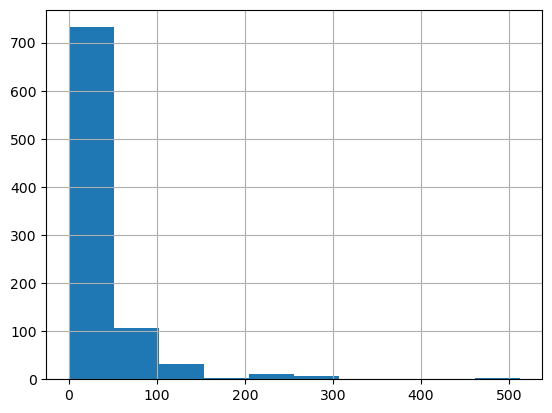

In [306]:
titanic["fare"].hist()

In [307]:
np.log(titanic["fare"]+1)

0      2.110213
1      4.280593
2      2.188856
3      3.990834
4      2.202765
         ...   
886    2.639057
887    3.433987
888    3.196630
889    3.433987
890    2.169054
Name: fare, Length: 891, dtype: float64

quartiles for fare

In [308]:

titanic["fare_qt"] = pd.qcut(titanic["fare"], q=4)

titanic["fare_qt"].value_counts().to_frame("fare_qt").sort_index()

,fare_qt
fare_qt,
"(-0.001, 7.91]",223
"(7.91, 14.454]",224
"(14.454, 31.0]",222
"(31.0, 512.329]",222


# 5-  Groups and Summarize

In [309]:
titanic.groupby("class").agg(
    fare_mdn = ("fare", lambda d: d.mean() )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/2559848895.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  titanic.groupby("class").agg(


,fare_mdn
class,
Third,13.675550
Second,20.662183
First,84.154687


In [310]:
titanic.groupby("sex").agg(
    age_mdn = ("age", lambda d: d.median() ),
    survival_prop = ("survived", lambda d: d.mean() )
)

,age_mdn,survival_prop
sex,,
female,27.0,0.742038
male,29.0,0.188908


In [311]:
titanic.groupby(["sex", "class"]).agg(
    survival_prop = ("survived", lambda d: d.mean() )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/1370979034.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  titanic.groupby(["sex", "class"]).agg(


survival_prop
sex    class                
female Third        0.500000
       Second       0.921053
       First        0.968085
male   Third        0.135447
       Second       0.157407
       First        0.368852

In [312]:
# same approach, but get VARIABLE and do value conts
titanic.groupby(["sex", "class"])["survived"].value_counts()

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/4181539213.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  titanic.groupby(["sex", "class"])["survived"].value_counts()


sex     class   survived
female  Third   0            72
                1            72
        Second  1            70
                0             6
        First   1            91
                0             3
male    Third   0           300
                1            47
        Second  0            91
                1            17
        First   0            77
                1            45
Name: count, dtype: int64

In [313]:
titanic.groupby(["sex", "class"])["survived"].value_counts(normalize=True)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/566005643.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  titanic.groupby(["sex", "class"])["survived"].value_counts(normalize=True)


sex     class   survived
female  Third   0           0.500000
                1           0.500000
        Second  1           0.921053
                0           0.078947
        First   1           0.968085
                0           0.031915
male    Third   0           0.864553
                1           0.135447
        Second  0           0.842593
                1           0.157407
        First   0           0.631148
                1           0.368852
Name: proportion, dtype: float64

class analysis

In [314]:
(
    titanic
    .groupby("class")
    .agg(
        n = ("fare", "size"), #total size col is irrelevant,
        mean_age = ("age", "mean"),
        mdn_fare = ("fare", "median"),
        surv_rate = ("survived", "mean")

    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/2720504168.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("class")


,n,mean_age,mdn_fare,surv_rate
class,,,,
Third,491,25.140620,8.0500,0.242363
Second,184,29.877630,14.2500,0.472826
First,216,38.233441,60.2875,0.629630


In [315]:
(
    titanic
    .groupby(["class", "sex"])
    .agg(
        n = ("fare", "size"), #total size col is irrelevant,
        mean_age = ("age", "mean"),
        mdn_fare = ("fare", "median"),
        surv_rate = ("survived", "mean")

    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/1978256471.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["class", "sex"])


n   mean_age  mdn_fare  surv_rate
class  sex                                        
Third  female  144  21.750000  12.47500   0.500000
       male    347  26.507589   7.92500   0.135447
Second female   76  28.722973  22.00000   0.921053
       male    108  30.740707  13.00000   0.157407
First  female   94  34.611765  82.66455   0.968085
       male    122  41.281386  41.26250   0.368852

In [316]:
(
    titanic
    .groupby("class")
    ["embarked"]
    .unique()
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/1215944794.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("class")


class
Third          [S, Q, C]
Second         [C, S, Q]
First     [C, S, nan, Q]
Name: embarked, dtype: object

prop of passengers per class

In [317]:
titanic["class"].value_counts(normalize=True)

class
Third     0.551066
First     0.242424
Second    0.206510
Name: proportion, dtype: float64

or using groupby and agg

In [318]:
(
    titanic
    .groupby("class")
    .agg(
        prop=("class", lambda d: len(d) / len(titanic))
    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/4243681171.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("class")


,prop
class,
Third,0.551066
Second,0.206510
First,0.242424


which age group has highest survival rate

In [319]:
pd.qcut(titanic["age"], 4)

0       (20.125, 28.0]
1         (28.0, 38.0]
2       (20.125, 28.0]
3         (28.0, 38.0]
4         (28.0, 38.0]
            ...       
886     (20.125, 28.0]
887    (0.419, 20.125]
888                NaN
889     (20.125, 28.0]
890       (28.0, 38.0]
Name: age, Length: 891, dtype: category
Categories (4, interval[float64, right]): [(0.419, 20.125] < (20.125, 28.0] < (28.0, 38.0] < (38.0, 80.0]]

In [320]:
(
    titanic
    .assign(
        age_group = pd.qcut(titanic["age"], 4)
    )
    .groupby("age_group")
    .agg(
        survival_rate = ("survived", lambda d: d.mean())
    )
    .reset_index()
    .sort_values("survival_rate", ascending=False)
    .iloc[0, ]
    ["age_group"]
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/2482711156.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("age_group")


Interval(0.419, 20.125, closed='right')

# 6 - Transformation

Add each passenger's class average fare without collapsing rows

In [321]:
titanic["fare_class_mean"] = (
    titanic
    .groupby("class")
    ["fare"]
    .transform(lambda d: d.mean())
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/1543408772.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("class")


[ ] Calculate each passenger's fare minus their class-average fare.

In [323]:
(
    titanic
    .assign(
        fare_centered_within_class = lambda d: d["fare"] - d["fare_class_mean"]
    )
)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,...,deck,embark_town,alive,alone,age_group,embarked_code,fare_gt_mdn,fare_qt,fare_class_mean,fare_centered_within_class
0,0,3,male,22.0,1,0,7.2500,S,Third,man,...,NaN,Southampton,no,False,young_adult,S,False,"(-0.001, 7.91]",13.675550,-6.425550
1,1,1,female,38.0,1,0,71.2833,C,First,woman,...,C,Cherbourg,yes,False,young_adult,Other,True,"(31.0, 512.329]",84.154687,-12.871387
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,...,NaN,Southampton,yes,True,young_adult,S,False,"(7.91, 14.454]",13.675550,-5.750550
3,1,1,female,35.0,1,0,53.1000,S,First,woman,...,C,Southampton,yes,False,young_adult,S,True,"(31.0, 512.329]",84.154687,-31.054687
4,0,3,male,35.0,0,0,8.0500,S,Third,man,...,NaN,Southampton,no,True,young_adult,S,False,"(7.91, 14.454]",13.675550,-5.625550
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,...,NaN,Southampton,no,True,young_adult,S,False,"(7.91, 14.454]",20.662183,-7.662183
887,1,1,female,19.0,0,0,30.0000,S,First,woman,...,B,Southampton,yes,True,young_adult,S,True,"(14.454, 31.0]",84.154687,-54.154687
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,...,NaN,Southampton,no,False,NaN,S,True,"(14.454, 31.0]",13.675550,9.774450
889,1,1,male,26.0,0,0,30.0000,C,First,man,...,C,Cherbourg,yes,True,young_adult,Other,True,"(14.454, 31.0]",84.154687,-54.154687


Standardize fare within each passenger class (within-class z-score).

The pattern here is that we must create a new column, so we want transform

- you can use assign to do it, or you can write a new column
- if using assign, it will use ROW INDEXES to match up. So, the lambda returns a series that needs to have row indexes. that means do NOT do THIS:         fare_within_sd = lambda d: d.groupby("class")["fare"].std()
- The problem with the above is it produces three values, one per class. If we did that, we'd need to left join it by class. 
- If using assign, transform is easier

ALWAYS REMEMBER THIS PATTERN

- when creating a new column, 
    - df.groupby("group")["column"].transform() to produce a series, then transform accepts the SERIES and outputs a matchign one
- when creating aggregates
    - df.groupby("group").agg()
    - df.groupby("group")["column"].std() or other function .... this calculates the stat by group and outputs a small series


In [331]:
(
    titanic
    .assign(
        fare_centered_within_class = lambda d: d["fare"] - d.groupby("class")["fare"].transform(lambda x: x.mean()),
        fare_std_within_class = lambda d: d.groupby("class")["fare"].transform(lambda x: x.std()),
        fare_z_within_class = lambda d: d["fare_centered_within_class"] / d["fare_std_within_class"]
    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/3110494298.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fare_centered_within_class = lambda d: d["fare"] - d.groupby("class")["fare"].transform(lambda x: x.mean()),
/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/3110494298.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fare_std_within_class = lambda d: d.groupby("class")["fare"].transform(lambda x: x.std()),


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,...,alive,alone,age_group,embarked_code,fare_gt_mdn,fare_qt,fare_class_mean,fare_centered_within_class,fare_std_within_class,fare_z_within_class
0,0,3,male,22.0,1,0,7.2500,S,Third,man,...,no,False,young_adult,S,False,"(-0.001, 7.91]",13.675550,-6.425550,11.778142,-0.545549
1,1,1,female,38.0,1,0,71.2833,C,First,woman,...,yes,False,young_adult,Other,True,"(31.0, 512.329]",84.154687,-12.871387,78.380373,-0.164217
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,...,yes,True,young_adult,S,False,"(7.91, 14.454]",13.675550,-5.750550,11.778142,-0.488239
3,1,1,female,35.0,1,0,53.1000,S,First,woman,...,yes,False,young_adult,S,True,"(31.0, 512.329]",84.154687,-31.054687,78.380373,-0.396205
4,0,3,male,35.0,0,0,8.0500,S,Third,man,...,no,True,young_adult,S,False,"(7.91, 14.454]",13.675550,-5.625550,11.778142,-0.477626
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,...,no,True,young_adult,S,False,"(7.91, 14.454]",20.662183,-7.662183,13.417399,-0.571063
887,1,1,female,19.0,0,0,30.0000,S,First,woman,...,yes,True,young_adult,S,True,"(14.454, 31.0]",84.154687,-54.154687,78.380373,-0.690922
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,...,no,False,NaN,S,True,"(14.454, 31.0]",13.675550,9.774450,11.778142,0.829880
889,1,1,male,26.0,0,0,30.0000,C,First,man,...,yes,True,young_adult,Other,True,"(14.454, 31.0]",84.154687,-54.154687,78.380373,-0.690922


Rank passengers by fare within each class.

.groupby("group")["column"].rank() is the equilvanet of a window function

Things to know
- ROW_NUMBER() method="first" (one value per row, e.g., 1,2,3)
- RANK() method="min" (preserves position and skips values when duplicates e.g., 1,1,3)
- DENSE_RANK() method="dense" (doesn't preserve position e.g., 1,1,2)

You can use ascending=True (default) to rank from bottom or ascending=False to rank from highest to lowest

In [ ]:
(
    titanic
    .assign(
        ranked_fare_within_class = lambda d: d.groupby("class")["fare"].rank(method="first")
    )
    .sort_values(["class", "ranked_fare_within_class"], ascending=[False, True])
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/150501147.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ranked_fare_within_class = lambda d: d.groupby("class")["fare"].rank(method="first")


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,...,deck,embark_town,alive,alone,age_group,embarked_code,fare_gt_mdn,fare_qt,fare_class_mean,ranked_fare_within_class
179,0,3,male,36.0,0,0,0.0000,S,Third,man,...,NaN,Southampton,no,True,young_adult,S,False,"(-0.001, 7.91]",13.675550,1.0
271,1,3,male,25.0,0,0,0.0000,S,Third,man,...,NaN,Southampton,yes,True,young_adult,S,False,"(-0.001, 7.91]",13.675550,2.0
302,0,3,male,19.0,0,0,0.0000,S,Third,man,...,NaN,Southampton,no,True,young_adult,S,False,"(-0.001, 7.91]",13.675550,3.0
597,0,3,male,49.0,0,0,0.0000,S,Third,man,...,NaN,Southampton,no,True,middle_age,S,False,"(-0.001, 7.91]",13.675550,4.0
378,0,3,male,20.0,0,0,4.0125,C,Third,man,...,NaN,Cherbourg,no,True,young_adult,Other,False,"(-0.001, 7.91]",13.675550,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
341,1,1,female,24.0,3,2,263.0000,S,First,woman,...,C,Southampton,yes,False,young_adult,S,True,"(31.0, 512.329]",84.154687,212.0
438,0,1,male,64.0,1,4,263.0000,S,First,man,...,C,Southampton,no,False,middle_age,S,True,"(31.0, 512.329]",84.154687,213.0
258,1,1,female,35.0,0,0,512.3292,C,First,woman,...,NaN,Cherbourg,yes,True,young_adult,Other,True,"(31.0, 512.329]",84.154687,214.0
679,1,1,male,36.0,0,1,512.3292,C,First,man,...,B,Cherbourg,yes,False,young_adult,Other,True,"(31.0, 512.329]",84.154687,215.0


What if, within class, we wanted to rank people on fare, and then among people with tied fares, rank them by sibsp. 
- in this case, do the sort FIRST on all your ranking columns, THEN do a gorup by cumcount() + 1 (since cumcount starts at 0)
- note that this numbers EVERY row. rank() returns NA when the underlying rank vsriable is na.

In [344]:
(
    titanic
    .sort_values(["fare", "sibsp"], ascending=[False, True])
    .assign(
        row_number = lambda d: d.groupby("class").cumcount() + 1
    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/690298428.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  row_number = lambda d: d.groupby("class").cumcount() + 1


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,...,deck,embark_town,alive,alone,age_group,embarked_code,fare_gt_mdn,fare_qt,fare_class_mean,row_number
258,1,1,female,35.0,0,0,512.3292,C,First,woman,...,NaN,Cherbourg,yes,True,young_adult,Other,True,"(31.0, 512.329]",84.154687,1
679,1,1,male,36.0,0,1,512.3292,C,First,man,...,B,Cherbourg,yes,False,young_adult,Other,True,"(31.0, 512.329]",84.154687,2
737,1,1,male,35.0,0,0,512.3292,C,First,man,...,B,Cherbourg,yes,True,young_adult,Other,True,"(31.0, 512.329]",84.154687,3
438,0,1,male,64.0,1,4,263.0000,S,First,man,...,C,Southampton,no,False,middle_age,S,True,"(31.0, 512.329]",84.154687,4
27,0,1,male,19.0,3,2,263.0000,S,First,man,...,C,Southampton,no,False,young_adult,S,True,"(31.0, 512.329]",84.154687,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
674,0,2,male,NaN,0,0,0.0000,S,Second,man,...,NaN,Southampton,no,True,NaN,S,False,"(-0.001, 7.91]",20.662183,183
732,0,2,male,NaN,0,0,0.0000,S,Second,man,...,NaN,Southampton,no,True,NaN,S,False,"(-0.001, 7.91]",20.662183,184
806,0,1,male,39.0,0,0,0.0000,S,First,man,...,A,Southampton,no,True,young_adult,S,False,"(-0.001, 7.91]",84.154687,214
815,0,1,male,NaN,0,0,0.0000,S,First,man,...,B,Southampton,no,True,NaN,S,False,"(-0.001, 7.91]",84.154687,215


Calculate each passenger's percentile rank for fare within their class.

we can use pct=True

In [350]:
(
    titanic
    .assign(
        fare_pctrank_within_class = lambda d: d.groupby("class")["fare"].rank(method="first", pct=True)
    )
    .sort_values(["class", "fare_pctrank_within_class"], ascending=[False, False])

    
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/3863987983.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fare_pctrank_within_class = lambda d: d.groupby("class")["fare"].rank(method="first", pct=True)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,...,deck,embark_town,alive,alone,age_group,embarked_code,fare_gt_mdn,fare_qt,fare_class_mean,fare_pctrank_within_class
737,1,1,male,35.0,0,0,512.3292,C,First,man,...,B,Cherbourg,yes,True,young_adult,Other,True,"(31.0, 512.329]",84.154687,1.000000
679,1,1,male,36.0,0,1,512.3292,C,First,man,...,B,Cherbourg,yes,False,young_adult,Other,True,"(31.0, 512.329]",84.154687,0.995370
258,1,1,female,35.0,0,0,512.3292,C,First,woman,...,NaN,Cherbourg,yes,True,young_adult,Other,True,"(31.0, 512.329]",84.154687,0.990741
438,0,1,male,64.0,1,4,263.0000,S,First,man,...,C,Southampton,no,False,middle_age,S,True,"(31.0, 512.329]",84.154687,0.986111
341,1,1,female,24.0,3,2,263.0000,S,First,woman,...,C,Southampton,yes,False,young_adult,S,True,"(31.0, 512.329]",84.154687,0.981481
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
378,0,3,male,20.0,0,0,4.0125,C,Third,man,...,NaN,Cherbourg,no,True,young_adult,Other,False,"(-0.001, 7.91]",13.675550,0.010183
597,0,3,male,49.0,0,0,0.0000,S,Third,man,...,NaN,Southampton,no,True,middle_age,S,False,"(-0.001, 7.91]",13.675550,0.008147
302,0,3,male,19.0,0,0,0.0000,S,Third,man,...,NaN,Southampton,no,True,young_adult,S,False,"(-0.001, 7.91]",13.675550,0.006110
271,1,3,male,25.0,0,0,0.0000,S,Third,man,...,NaN,Southampton,yes,True,young_adult,S,False,"(-0.001, 7.91]",13.675550,0.004073


[ ] Calculate cumulative fare after sorting passengers by fare.

In [352]:
(
    titanic
    .sort_values("fare")
    ["fare"].cumsum()
)

271        0.0000
597        0.0000
302        0.0000
633        0.0000
277        0.0000
          ...    
438    26893.9617
341    27156.9617
737    27669.2909
258    28181.6201
679    28693.9493
Name: fare, Length: 891, dtype: float64

[ ] Calculate the difference in fare between consecutive passengers after sorting.

Lead / lag functions in pandas are all done via .shift()

Run this on a SERIES

.shift(1) looks BACK 1
.shift(-1) looks AT NEXT

SORT FIRST

In [359]:
(
    titanic
    .sort_values("fare")
    .assign(
        next_fare = lambda d: d["fare"].shift(-1),
        diff_from_next_fare = lambda d: d["fare"]-d["next_fare"]
    )
)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,...,embark_town,alive,alone,age_group,embarked_code,fare_gt_mdn,fare_qt,fare_class_mean,next_fare,diff_from_next_fare
271,1,3,male,25.0,0,0,0.0000,S,Third,man,...,Southampton,yes,True,young_adult,S,False,"(-0.001, 7.91]",13.675550,0.0000,0.0000
597,0,3,male,49.0,0,0,0.0000,S,Third,man,...,Southampton,no,True,middle_age,S,False,"(-0.001, 7.91]",13.675550,0.0000,0.0000
302,0,3,male,19.0,0,0,0.0000,S,Third,man,...,Southampton,no,True,young_adult,S,False,"(-0.001, 7.91]",13.675550,0.0000,0.0000
633,0,1,male,NaN,0,0,0.0000,S,First,man,...,Southampton,no,True,NaN,S,False,"(-0.001, 7.91]",84.154687,0.0000,0.0000
277,0,2,male,NaN,0,0,0.0000,S,Second,man,...,Southampton,no,True,NaN,S,False,"(-0.001, 7.91]",20.662183,0.0000,0.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
438,0,1,male,64.0,1,4,263.0000,S,First,man,...,Southampton,no,False,middle_age,S,True,"(31.0, 512.329]",84.154687,263.0000,0.0000
341,1,1,female,24.0,3,2,263.0000,S,First,woman,...,Southampton,yes,False,young_adult,S,True,"(31.0, 512.329]",84.154687,512.3292,-249.3292
737,1,1,male,35.0,0,0,512.3292,C,First,man,...,Cherbourg,yes,True,young_adult,Other,True,"(31.0, 512.329]",84.154687,512.3292,0.0000
258,1,1,female,35.0,0,0,512.3292,C,First,woman,...,Cherbourg,yes,True,young_adult,Other,True,"(31.0, 512.329]",84.154687,512.3292,0.0000


There's also .diff(-1) which shorthands this calculation

In [360]:
(
    titanic
    .sort_values("fare")
    .assign(
        diff_from_next_fare = lambda d: d["fare"].diff(-1)
    )
)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,...,deck,embark_town,alive,alone,age_group,embarked_code,fare_gt_mdn,fare_qt,fare_class_mean,diff_from_next_fare
271,1,3,male,25.0,0,0,0.0000,S,Third,man,...,NaN,Southampton,yes,True,young_adult,S,False,"(-0.001, 7.91]",13.675550,0.0000
597,0,3,male,49.0,0,0,0.0000,S,Third,man,...,NaN,Southampton,no,True,middle_age,S,False,"(-0.001, 7.91]",13.675550,0.0000
302,0,3,male,19.0,0,0,0.0000,S,Third,man,...,NaN,Southampton,no,True,young_adult,S,False,"(-0.001, 7.91]",13.675550,0.0000
633,0,1,male,NaN,0,0,0.0000,S,First,man,...,NaN,Southampton,no,True,NaN,S,False,"(-0.001, 7.91]",84.154687,0.0000
277,0,2,male,NaN,0,0,0.0000,S,Second,man,...,NaN,Southampton,no,True,NaN,S,False,"(-0.001, 7.91]",20.662183,0.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
438,0,1,male,64.0,1,4,263.0000,S,First,man,...,C,Southampton,no,False,middle_age,S,True,"(31.0, 512.329]",84.154687,0.0000
341,1,1,female,24.0,3,2,263.0000,S,First,woman,...,C,Southampton,yes,False,young_adult,S,True,"(31.0, 512.329]",84.154687,-249.3292
737,1,1,male,35.0,0,0,512.3292,C,First,man,...,B,Cherbourg,yes,True,young_adult,Other,True,"(31.0, 512.329]",84.154687,0.0000
258,1,1,female,35.0,0,0,512.3292,C,First,woman,...,NaN,Cherbourg,yes,True,young_adult,Other,True,"(31.0, 512.329]",84.154687,0.0000


Identify the top three highest-paying passengers within each class.

In [364]:
(
    titanic
    .assign(
        fare_row_number_within_class = lambda d: d.groupby("class")["fare"].rank(method="first", ascending=False)
    )
    .loc[
        lambda d: d["fare_row_number_within_class"].isin([1,2,3])
    ]
    .sort_values(["class", "fare_row_number_within_class"], ascending=[False, True])
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/910245846.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fare_row_number_within_class = lambda d: d.groupby("class")["fare"].rank(method="first", ascending=False)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,...,deck,embark_town,alive,alone,age_group,embarked_code,fare_gt_mdn,fare_qt,fare_class_mean,fare_row_number_within_class
258,1,1,female,35.0,0,0,512.3292,C,First,woman,...,NaN,Cherbourg,yes,True,young_adult,Other,True,"(31.0, 512.329]",84.154687,1.0
679,1,1,male,36.0,0,1,512.3292,C,First,man,...,B,Cherbourg,yes,False,young_adult,Other,True,"(31.0, 512.329]",84.154687,2.0
737,1,1,male,35.0,0,0,512.3292,C,First,man,...,B,Cherbourg,yes,True,young_adult,Other,True,"(31.0, 512.329]",84.154687,3.0
72,0,2,male,21.0,0,0,73.5000,S,Second,man,...,NaN,Southampton,no,True,young_adult,S,True,"(31.0, 512.329]",20.662183,1.0
120,0,2,male,21.0,2,0,73.5000,S,Second,man,...,NaN,Southampton,no,False,young_adult,S,True,"(31.0, 512.329]",20.662183,2.0
385,0,2,male,18.0,0,0,73.5000,S,Second,man,...,NaN,Southampton,no,True,young_adult,S,True,"(31.0, 512.329]",20.662183,3.0
159,0,3,male,NaN,8,2,69.5500,S,Third,man,...,NaN,Southampton,no,False,NaN,S,True,"(31.0, 512.329]",13.675550,1.0
180,0,3,female,NaN,8,2,69.5500,S,Third,woman,...,NaN,Southampton,no,False,NaN,S,True,"(31.0, 512.329]",13.675550,2.0
201,0,3,male,NaN,8,2,69.5500,S,Third,man,...,NaN,Southampton,no,False,NaN,S,True,"(31.0, 512.329]",13.675550,3.0


# 7 - pivot and reshape

Things we will want here in clude
- .groupby().agg() .... grouped summaries in long format
- .pivot_table() .... summaries with groups as ROWS AND COLUMNS. similar to summarize and then pivot_wider() in R
- . pd.crosstab() .... similar to table() or prop.table() in R
- .melt() .... wide to long... pivot_longer()
- .pivot() .... long to wide WITHOUT AGGREGATION ...pivot_wider()
- .unstack .... move an index level into columns ... similar ot pivot_wider()
- .stack .... move a column intoa n index level ... similar to pivot_longer()

for a summary matrix, the pattern is:
```
df.pivot_table()
    index="row_category",       # one analysis column
    columns="column_category",  # one analysis column
    values="measurement",       # the VALUE 
    aggfunc="mean"              # what we are using as the function
```

In [371]:
#example

titanic.pivot_table(
    index = "class",
    columns="embarked",
    values="survived",
    aggfunc=lambda d: d.mean()
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/2919797295.py:3: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  titanic.pivot_table(


embarked,C,Q,S
class,,,
Third,0.378788,0.375000,0.189802
Second,0.529412,0.666667,0.463415
First,0.694118,0.500000,0.582677


In [374]:
# also easy to do that in long format and pivot wider
(
    titanic
    .groupby(["class", "embarked"])
    .agg(
        mean_survival = ("survived", lambda d: d.mean())
    )
    .unstack("embarked")
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/493661564.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["class", "embarked"])


mean_survival                    
embarked             C         Q         S
class                                     
Third         0.378788  0.375000  0.189802
Second        0.529412  0.666667  0.463415
First         0.694118  0.500000  0.582677

In [379]:
# or we can pivot wider with .pivot
# trick is that index needs to move into data
(
    titanic
    .groupby(["class", "embarked"])
    .agg(
        mean_survival = ("survived", lambda d: d.mean())
    )
    .reset_index()
    .pivot(
        index="class",
        columns="embarked",
        values="mean_survival"
    )
)


/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/188091829.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["class", "embarked"])


embarked,C,Q,S
class,,,
Third,0.378788,0.375000,0.189802
Second,0.529412,0.666667,0.463415
First,0.694118,0.500000,0.582677


for crosstabs, the pattern is
```
pd.crosstab(
    df["row_category"],
    df["column_category"],
    normalize="index"|"columns"|"all"
)
```

- omit normalize for counts
- normalize can be 
    - "index" for row props
    - "columns" for col props
    - "all" for overall proportions


for wide --> long

```
df.melt(
    id_vars=["cols_identifying_rows"], #current rows
    value_vars=["measure_a", "measure_b"], #current inputs
    var_name = "old_varnames_as_var",   # new place to put intput names
    value_name = "old_values_as_var"    # new place to put value names
)
```
for long --> wide

```
df.pivot(
    index="identifier", # keep as rows
    columns="measure", #this will turn into new columns
    values="value"
)
```

Special case --- if you have nested indexes, you can pivot one of them into columns with unstack

In [366]:
#example of unstack
eg_series = (
    titanic.groupby(["class", "embarked"])["fare"].mean()
)
eg_series

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/1755832444.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  titanic.groupby(["class", "embarked"])["fare"].mean()


class   embarked
Third   C            11.214083
        Q            11.183393
        S            14.644083
Second  C            25.358335
        Q            12.350000
        S            20.327439
First   C           104.718529
        Q            90.000000
        S            70.364862
Name: fare, dtype: float64

In [367]:
#We can easily pivot that wider with unstack
eg_series.unstack("class")

class,Third,Second,First
embarked,,,
C,11.214083,25.358335,104.718529
Q,11.183393,12.350000,90.000000
S,14.644083,20.327439,70.364862


In [368]:
eg_series.unstack("class")

class,Third,Second,First
embarked,,,
C,11.214083,25.358335,104.718529
Q,11.183393,12.350000,90.000000
S,14.644083,20.327439,70.364862


Lets' do a simple melt

In [417]:
#first make a ide dataframe
temp1 = (
    titanic
    .groupby(["class", "sex"])
    .agg(
        npass = ("class", lambda d: len(d))
    )
    .reset_index()
    .pivot(
        index="class",
        columns=["sex"],
        values="npass",
        )
)
display(temp1)

#make it longer

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/2430329758.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["class", "sex"])


sex,female,male
class,,
Third,144,347
Second,76,108
First,94,122


In [422]:
# melt it

(
    temp1
    .reset_index()
    .melt(
        id_vars=["class"], #what identifies rows
        value_vars = ["female", "male"],
        var_name="sex",
        value_name = "count"
    )
    
)

,class,sex,count
0,Third,female,144
1,Second,female,76
2,First,female,94
3,Third,male,347
4,Second,male,108
5,First,male,122


Practice! first, use multiple columns to go wide, then make longer with a melt

In [423]:
#first make a ide dataframe
temp1 = (
    titanic
    .groupby(["class", "sex", "embarked"])
    .agg(
        npass = ("class", lambda d: len(d))
    )
    .reset_index()
    .pivot(
        index="class",
        columns=['embarked', "sex"],
        values="npass",
        )
)
display(temp1)

#make it longer

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/207802974.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["class", "sex", "embarked"])


embarked,C,Q,S,C,Q,S
sex,female,female,female,male,male,male
class,,,,,,
Third,23,33,88,43,39,265
Second,7,2,67,10,1,97
First,43,1,48,42,1,79


In [404]:
# method 1 = stack
(
    temp1
    .stack("sex")   
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/1855840810.py:4: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  .stack("sex")


embarked        C   Q    S
class  sex                
Third  female  23  33   88
       male    43  39  265
Second female   7   2   67
       male    10   1   97
First  female  43   1   48
       male    42   1   79

In [425]:
# you can also 
# method 1 = stack
(
    temp1
    .stack("sex")
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/2602865544.py:5: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  .stack("sex")


embarked        C   Q    S
class  sex                
Third  female  23  33   88
       male    43  39  265
Second female   7   2   67
       male    10   1   97
First  female  43   1   48
       male    42   1   79

In [430]:
temp1

embarked,C,Q,S,C,Q,S
sex,female,female,female,male,male,male
class,,,,,,
Third,23,33,88,43,39,265
Second,7,2,67,10,1,97
First,43,1,48,42,1,79


In [432]:
(
    temp1
    .rename_axis(columns=["embarked", "sex"])
    .reset_index()
    )

embarked,class,C,Q,S,C,Q,S
sex,,female,female,female,male,male,male
0,Third,23,33,88,43,39,265
1,Second,7,2,67,10,1,97
2,First,43,1,48,42,1,79


In [434]:
# method 2 = melt
# too complex!

Now for test questions!

Create a survival-rate table with class as rows and sex as columns.

In [381]:
# method 1 - long format first, then pivot wider
(
    titanic
    .groupby(["class", "sex"])
    .agg(
        surv = ("survived", lambda d: d.mean())
    )
    .unstack("sex")
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/2429240955.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["class", "sex"])


surv          
sex       female      male
class                     
Third   0.500000  0.135447
Second  0.921053  0.157407
First   0.968085  0.368852

In [384]:
# method 2 - same thing but with pivot wider ... get indexes into df first
(
    titanic
    .groupby(["class", "sex"])
    .agg(
        surv = ("survived", lambda d: d.mean())
    )
    .reset_index()
    .pivot(
        index="class",
        columns="sex",
        values="surv"
    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/2532384574.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["class", "sex"])


sex,female,male
class,,
Third,0.500000,0.135447
Second,0.921053,0.157407
First,0.968085,0.368852


In [385]:
# method 3 - pivot table
(
    titanic
    .pivot_table(
        index="class",
        columns="embarked",
        values="survived",
        aggfunc = lambda d: d.mean()
    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/446696868.py:4: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(


embarked,C,Q,S
class,,,
Third,0.378788,0.375000,0.189802
Second,0.529412,0.666667,0.463415
First,0.694118,0.500000,0.582677


Create a passenger-count table with class as rows and embarkation port as columns.

In [ ]:
# method 1a -- same as above 3 methods, but with a .size()
(
    titanic
    .groupby(["class", "embarked"])
    .agg(
        passengers = ("class", lambda d: len(d))
    )
    .unstack("embarked")
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/3721466539.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["class", "embarked"])


passengers         
embarked          C   Q    S
class                       
Third            66  72  353
Second           17   3  164
First            85   2  127

In [ ]:
#method 1b - with pivot
(
    titanic
    .groupby(["class", "embarked"])
    .agg(
        passengers = ("class", lambda d: len(d)) #dummy variable sinc we are counting people
    )
    .reset_index()
    .pivot(
        index="class",
        columns="embarked",
        values="passengers"
    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/440611574.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["class", "embarked"])


embarked,C,Q,S
class,,,
Third,66,72,353
Second,17,3,164
First,85,2,127


In [ ]:
# method 1c - with pivot table
(
    titanic
    .pivot_table(
        index="class",
        columns="embarked",
        values="fare", #dummy variable since we are counting people
        aggfunc=lambda d: len(d)
    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/79597072.py:4: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(


embarked,C,Q,S
class,,,
Third,66,72,353
Second,17,3,164
First,85,2,127


In [ ]:
# Method 2 - crosstabs

pd.crosstab(
    index=titanic["class"],
    columns=titanic["embarked"]
)

embarked,C,Q,S
class,,,
Third,66,72,353
Second,17,3,164
First,85,2,127


Create a pivot table showing mean age by sex and survival status.

In [435]:
(
    titanic
    .pivot_table(
        index="sex",
        columns="survived",
        values="age",
        aggfunc=lambda d: d.mean()
    )
)

survived,0,1
sex,,
female,25.046875,28.847716
male,31.618056,27.276022


In [445]:
# for fun, renaming
(
    titanic
    .pivot_table(
        index="sex",
        columns="survived",
        values="age",
        aggfunc=lambda d: d.mean()
    )
    .reset_index()
    .rename(columns={
        0: "Did Not Survive",
        1: "Survived",
        "sex": "Sex"
        })
    .rename_axis(index=None, columns=None)
    .assign(
        Sex = lambda d: d["Sex"].map({"female": "Female", "male": "Male"})
    )
    .round(2)
)

,Sex,Did Not Survive,Survived
0,Female,25.05,28.85
1,Male,31.62,27.28


Create a pivot table with multiple summary statistics for fare.

In [ ]:
# manual control with .agg

(
    titanic
    .groupby(["class", "embarked"])
    .agg(
        mean = ("fare", lambda d: d.mean()),
        median = ("fare", lambda d: d.median()),
        std = ("fare", lambda d: d.std()),
        n = ("fare", lambda d: d.size),     #NO PAREN ON SIZE!!
        min = ("fare", lambda d: min(d)),
        max = ("fare", lambda d: max(d))
    )
    .round(2)
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/2424983692.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["class", "embarked"])


mean  median    std    n    min     max
class  embarked                                           
Third  C          11.21    7.90   4.87   66   4.01   22.36
       Q          11.18    7.75   6.72   72   6.75   29.12
       S          14.64    8.05  13.28  353   0.00   69.55
Second C          25.36   24.00  11.35   17  12.00   41.58
       Q          12.35   12.35   0.00    3  12.35   12.35
       S          20.33   13.50  13.63  164   0.00   73.50
First  C         104.72   78.27  99.09   85  26.55  512.33
       Q          90.00   90.00   0.00    2  90.00   90.00
       S          70.36   52.00  58.81  127   0.00  263.00

Convert a wide summary table into long format.

In [471]:
temp1 = (
    titanic
    .pivot_table(
        index="class",
        columns = "embarked",
        values = "survived",
        aggfunc = lambda d: d.mean()
    )
)
display(temp1)

display(
    temp1
    .stack("embarked")
    )


temp2 = (
    temp1
    .reset_index()
    .melt(
        id_vars="class",
        value_vars=["C", "Q", "S"],
        value_name = "survival_rate",
        var_name = "Embarked"
    )
)

display(temp2)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/1952040201.py:3: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(


embarked,C,Q,S
class,,,
Third,0.378788,0.375000,0.189802
Second,0.529412,0.666667,0.463415
First,0.694118,0.500000,0.582677


class   embarked
Third   C           0.378788
        Q           0.375000
        S           0.189802
Second  C           0.529412
        Q           0.666667
        S           0.463415
First   C           0.694118
        Q           0.500000
        S           0.582677
dtype: float64

,class,Embarked,survival_rate
0,Third,C,0.378788
1,Second,C,0.529412
2,First,C,0.694118
3,Third,Q,0.375000
4,Second,Q,0.666667
5,First,Q,0.500000
6,Third,S,0.189802
7,Second,S,0.463415
8,First,S,0.582677


In [473]:
#get temp2 back to wide

(
    temp2
    .pivot(
        index="class",
        columns="Embarked",
        values="survival_rate"
    )
    )

Embarked,C,Q,S
class,,,
Third,0.378788,0.375000,0.189802
Second,0.529412,0.666667,0.463415
First,0.694118,0.500000,0.582677


Create a contingency table of sex × survival.

In [474]:
pd.crosstab(
    index=titanic["sex"],
    columns=titanic["survived"]
)

survived,0,1
sex,,
female,81,233
male,468,109


Create a contingency table of class × survival with row percentages.

In [482]:
pd.crosstab(
    index=titanic["class"],
    columns=titanic["survived"]
)

survived,0,1
class,,
Third,372,119
Second,97,87
First,80,136


Bonus: crosstab with multiple variables

In [484]:
pd.crosstab(
    index=[
        titanic["class"],
        titanic["sex"]
    ],
    columns=titanic["survived"]
)

survived         0   1
class  sex            
Third  female   72  72
       male    300  47
Second female    6  70
       male     91  17
First  female    3  91
       male     77  45

# 8 - Joins and combining data

Core playbook

- `.merge()` or `pd.merge()` joins dataframe using keys
- `.join()` joins dataframe using index values
- `pd.concat([a, b], axis=0|1, ignore_index=True)` 

```
df1.merge(
    df2,
    on="key", #or [key1, key2] for multi-key-joins
    how="left"|"right"|"inner"|"outer",
    validate="X_to_X", #X can be many or one
    indicator=True #column to say if row matched
)
```

if differnet names:
`left_on=` and `right_on=`

indicator gives a `_merge` column indicating which joined ("both" "left_only" "right_only)

Join by key
`df1.merge(df2, on="key", how="left")`

Join using multiple keys
`df1.merge(df2, on=["key1", "key2"])`

Protect against accidental duplicate matches
`df1.merge(df2, on="key", validate="many_to_one")`

Diagnose unmatched records
`df1.merge(df2, on="key", how="left", indicator=True)`

Stack rows
`pd.concat([df1, df2], ignore_index=True)`

Combine columns (by index)
`pd.concat([df1, df2], axis=1)`

Map lookup values
`df["code"].map(mapping_dict)`

Check unique keys
`df["key"].is_unique`

Check duplicate keys
`df.duplicated(subset=["key"]).sum()`

Some simple mapping without a join

In [ ]:
# sipmly recode an existing variable with a dict!
(
    titanic
    .assign(
        port_name = lambda d: d["embarked"].map({"C": "Cherbourg", "S": "Southampton", "Q": "Queenstown"})
    )
)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,...,deck,embark_town,alive,alone,age_group,embarked_code,fare_gt_mdn,fare_qt,fare_class_mean,port_name
0,0,3,male,22.0,1,0,7.2500,S,Third,man,...,NaN,Southampton,no,False,young_adult,S,False,"(-0.001, 7.91]",13.675550,Southampton
1,1,1,female,38.0,1,0,71.2833,C,First,woman,...,C,Cherbourg,yes,False,young_adult,Other,True,"(31.0, 512.329]",84.154687,Cherbourg
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,...,NaN,Southampton,yes,True,young_adult,S,False,"(7.91, 14.454]",13.675550,Southampton
3,1,1,female,35.0,1,0,53.1000,S,First,woman,...,C,Southampton,yes,False,young_adult,S,True,"(31.0, 512.329]",84.154687,Southampton
4,0,3,male,35.0,0,0,8.0500,S,Third,man,...,NaN,Southampton,no,True,young_adult,S,False,"(7.91, 14.454]",13.675550,Southampton
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,...,NaN,Southampton,no,True,young_adult,S,False,"(7.91, 14.454]",20.662183,Southampton
887,1,1,female,19.0,0,0,30.0000,S,First,woman,...,B,Southampton,yes,True,young_adult,S,True,"(14.454, 31.0]",84.154687,Southampton
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,...,NaN,Southampton,no,False,NaN,S,True,"(14.454, 31.0]",13.675550,Southampton
889,1,1,male,26.0,0,0,30.0000,C,First,man,...,C,Cherbourg,yes,True,young_adult,Other,True,"(14.454, 31.0]",84.154687,Cherbourg


Now to test questions

Create a separate DataFrame containing mean fare by class.

In [488]:
df1 = (
    titanic
    .groupby("class")
    .agg(
        mean_fare_by_class = ("fare", "mean")
    )
)

df1

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_4848/1213143968.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("class")


,mean_fare_by_class
class,
Third,13.675550
Second,20.662183
First,84.154687


Left-join that summary back onto the passenger-level dataset.

In [495]:
joined = (
    titanic
    .merge(
        df1, 
        on="class",
        how="left",
        validate="many_to_one"
    )
)

joined

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,...,deck,embark_town,alive,alone,age_group,embarked_code,fare_gt_mdn,fare_qt,fare_class_mean,mean_fare_by_class
0,0,3,male,22.0,1,0,7.2500,S,Third,man,...,NaN,Southampton,no,False,young_adult,S,False,"(-0.001, 7.91]",13.675550,13.675550
1,1,1,female,38.0,1,0,71.2833,C,First,woman,...,C,Cherbourg,yes,False,young_adult,Other,True,"(31.0, 512.329]",84.154687,84.154687
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,...,NaN,Southampton,yes,True,young_adult,S,False,"(7.91, 14.454]",13.675550,13.675550
3,1,1,female,35.0,1,0,53.1000,S,First,woman,...,C,Southampton,yes,False,young_adult,S,True,"(31.0, 512.329]",84.154687,84.154687
4,0,3,male,35.0,0,0,8.0500,S,Third,man,...,NaN,Southampton,no,True,young_adult,S,False,"(7.91, 14.454]",13.675550,13.675550
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,...,NaN,Southampton,no,True,young_adult,S,False,"(7.91, 14.454]",20.662183,20.662183
887,1,1,female,19.0,0,0,30.0000,S,First,woman,...,B,Southampton,yes,True,young_adult,S,True,"(14.454, 31.0]",84.154687,84.154687
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,...,NaN,Southampton,no,False,NaN,S,True,"(14.454, 31.0]",13.675550,13.675550
889,1,1,male,26.0,0,0,30.0000,C,First,man,...,C,Cherbourg,yes,True,young_adult,Other,True,"(14.454, 31.0]",84.154687,84.154687


In [496]:
assert len(joined) == len(titanic)

Create a lookup table mapping embarkation codes to port names. Then, join to passenger data

In [502]:
ports = pd.DataFrame({
    "port": ["Queensland", "Southampton", "Cherbourg",],
    "Embarked": ["Q", "S", "C"]
    })

ports

,port,Embarked
0,Queensland,Q
1,Southampton,S
2,Cherbourg,C


In [ ]:
(
    titanic
    .merge(
        ports, 
        left_on="embarked", 
        right_on="Embarked",
        how="left",
        validate="many_to_one"
    )
)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,...,embark_town,alive,alone,age_group,embarked_code,fare_gt_mdn,fare_qt,fare_class_mean,port,Embarked
0,0,3,male,22.0,1,0,7.2500,S,Third,man,...,Southampton,no,False,young_adult,S,False,"(-0.001, 7.91]",13.675550,Southampton,S
1,1,1,female,38.0,1,0,71.2833,C,First,woman,...,Cherbourg,yes,False,young_adult,Other,True,"(31.0, 512.329]",84.154687,Cherbourg,C
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,...,Southampton,yes,True,young_adult,S,False,"(7.91, 14.454]",13.675550,Southampton,S
3,1,1,female,35.0,1,0,53.1000,S,First,woman,...,Southampton,yes,False,young_adult,S,True,"(31.0, 512.329]",84.154687,Southampton,S
4,0,3,male,35.0,0,0,8.0500,S,Third,man,...,Southampton,no,True,young_adult,S,False,"(7.91, 14.454]",13.675550,Southampton,S
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,...,Southampton,no,True,young_adult,S,False,"(7.91, 14.454]",20.662183,Southampton,S
887,1,1,female,19.0,0,0,30.0000,S,First,woman,...,Southampton,yes,True,young_adult,S,True,"(14.454, 31.0]",84.154687,Southampton,S
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,...,Southampton,no,False,NaN,S,True,"(14.454, 31.0]",13.675550,Southampton,S
889,1,1,male,26.0,0,0,30.0000,C,First,man,...,Cherbourg,yes,True,young_adult,Other,True,"(14.454, 31.0]",84.154687,Cherbourg,C


Split the dataset into male and female passengers, then concatenate them back together.

In [512]:
male = (
    titanic.loc[titanic["sex"]=="male"]
)

female = (
    titanic.loc[titanic["sex"]=="female"]
)

print(male.shape)
print(female.shape)

(577, 20)
(314, 20)


In [ ]:
output = pd.concat(
    [male, female], axis=0
).sort_index() #puts back in row order
assert output.equals(titanic)

Identify unmatched rows after a join.

In [532]:
# incomplete lookup table

ports_bad = pd.DataFrame({
    "port": ["Cherbourg", "Southampton"],
    "embarked": ["C", "S"]
})

test_df = (
    titanic
    .merge(ports_bad, how="left", on="embarked", validate="many_to_one", indicator=True)
)

assert(titanic.shape[0] == test_df.shape[0])

test_df.loc[test_df["_merge"] != "both" ]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,...,embark_town,alive,alone,age_group,embarked_code,fare_gt_mdn,fare_qt,fare_class_mean,port,_merge
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,...,Queenstown,no,True,NaN,Other,False,"(7.91, 14.454]",13.675550,NaN,left_only
16,0,3,male,2.0,4,1,29.1250,Q,Third,child,...,Queenstown,no,False,child,Other,True,"(14.454, 31.0]",13.675550,NaN,left_only
22,1,3,female,15.0,0,0,8.0292,Q,Third,child,...,Queenstown,yes,True,child,Other,False,"(7.91, 14.454]",13.675550,NaN,left_only
28,1,3,female,NaN,0,0,7.8792,Q,Third,woman,...,Queenstown,yes,True,NaN,Other,False,"(-0.001, 7.91]",13.675550,NaN,left_only
32,1,3,female,NaN,0,0,7.7500,Q,Third,woman,...,Queenstown,yes,True,NaN,Other,False,"(-0.001, 7.91]",13.675550,NaN,left_only
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
825,0,3,male,NaN,0,0,6.9500,Q,Third,man,...,Queenstown,no,True,NaN,Other,False,"(-0.001, 7.91]",13.675550,NaN,left_only
828,1,3,male,NaN,0,0,7.7500,Q,Third,man,...,Queenstown,yes,True,NaN,Other,False,"(-0.001, 7.91]",13.675550,NaN,left_only
829,1,1,female,62.0,0,0,80.0000,NaN,First,woman,...,NaN,yes,True,middle_age,unassigned,True,"(31.0, 512.329]",84.154687,NaN,left_only
885,0,3,female,39.0,0,5,29.1250,Q,Third,woman,...,Queenstown,no,False,young_adult,Other,True,"(14.454, 31.0]",13.675550,NaN,left_only


In [537]:
titanic["fare"].to_frame("fare")

,fare
0,7.2500
1,71.2833
2,7.9250
3,53.1000
4,8.0500
...,...
886,13.0000
887,30.0000
888,23.4500
889,30.0000
